# Hệ thống Phân tích Cảm xúc TikTok Song ngữ (Tiếng Việt & Tiếng Anh)

- **Dữ liệu thu thập (`data/<post_id>/`):** Tự động tải video (`video.mp4`), `metadata.json` và bình luận thô (`raw_comments.csv`).
- **Giai đoạn 1 — AI Đầu vào (`gemma4-e2b-opt`):** Đọc khung hình + lời thoại Whisper (tự nhận diện VI/EN) + caption để trích xuất 8 trường ngữ cảnh bài đăng.
- **Giai đoạn 2 — Tiền xử lý & Lọc nhiễu (`src/preprocessing/text_cleaner.py`):** Nhận diện ngôn ngữ (`vi` / `en`), lọc bình luận nhiễu (`@tag` bạn bè, tên riêng đơn lẻ qua `underthesea`, URL, seeding, spam quảng cáo, ngôn ngữ khác `FILTERED_UNSUPPORTED_LANG`).
- **Giai đoạn 3 — Lõi ML & Deep Learning (`src/models/classical_ml.py` + `sentiment_engine.py`):**
  - **Tiếng Việt:** `TF-IDF (NB/LR/SVM)` + `Vietnamese Lexicon` + `ViSoBERT` + `PhoBERT` + `PhoBERT Emotion (7 cung bậc)`.
  - **Tiếng Anh:** `TF-IDF (NB/LR/SVM)` + `English Lexicon` + `Twitter-RoBERTa` + `DistilRoBERTa Emotion (7 cung bậc)`.
  - **Thang điểm kép nhất quán:** `polarity_score` (`-1.0..+1.0`), `score_5` (`1..5`), `score_10` (`0..10`).
- **Giai đoạn 4 — AI Đầu ra (`src/models/gemma_auditor.py`):** `gemma4-e2b-opt` thẩm định thực tế **100% bình luận hợp lệ**, phát hiện nói mỉa (`sarcasm`) và xuất kết quả cuối cùng ra **`outputs/<post_id>/`**.

> Đảm bảo container Ollama `gemma4-e2b` đang chạy (`docker compose up -d` trong `AI_Local/gemma4-e2b`) trước khi chạy.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from src.pipeline import SentimentPipeline
from src.visualization import plot_sentiment_dashboard

# === NHẬP LINK VIDEO TIKTOK ===
TIKTOK_URL = input("Nhập link video TikTok: ").strip()

# Cấu hình hệ thống
ENABLE_AUDIO = True
RUN_AI_AUDIT = True          # Gemma 4 E2B thẩm định thực tế ở đầu ra
AUDIT_LIMIT = None           # None = chấm 100% bình luận hợp lệ
MAX_COMMENTS = 200
DEDUPLICATE_STATS = False    # True nếu muốn loại bỏ bình luận copy-paste khỏi tỷ lệ %
DATA_DIR = Path("data")      # Nơi lưu toàn bộ dữ liệu thu thập thô
OUTPUT_DIR = Path("outputs") # Nơi xuất kết quả cuối cùng sau xử lý

In [2]:
# === CHẠY TOÀN BỘ PIPELINE 4 GIAI ĐOẠN ===
if not TIKTOK_URL:
    raise ValueError("Vui lòng nhập link video TikTok vào biến TIKTOK_URL.")

pipeline = SentimentPipeline()
report = pipeline.run(
    tiktok_url=TIKTOK_URL,
    enable_audio=ENABLE_AUDIO,
    run_ai_audit=RUN_AI_AUDIT,
    audit_limit=AUDIT_LIMIT,
    max_comments=MAX_COMMENTS,
    deduplicate_stats=DEDUPLICATE_STATS,
    data_dir=DATA_DIR,
    output_dir=OUTPUT_DIR,
)

run_name = report["run_name"]
print(f"-> Dữ liệu thu thập lưu tại: {DATA_DIR / run_name}")
print(f"-> Kết quả xử lý xuất tại  : {OUTPUT_DIR / run_name}")

if report.get("media_analysis"):
    print("\n=== GIAI ĐOẠN 1: NGỮ CẢNH VIDEO (GEMMA 4 E2B) ===")
    print(json.dumps(report["media_analysis"], ensure_ascii=False, indent=2))

[Bước 0] Đang tải video & metadata vào data\7709458511838612744...
[Bước 0] Đang thu thập bình luận vào data\7709458511838612744\raw_comments.csv...
Đang mở trình duyệt tới: https://www.tiktok.com/@ducreaction/video/7709458511838612744?is_from_webapp=1&sender_device=pc&web_id=7705826630715655698

[Tạm dừng] Trên cửa sổ trình duyệt vừa mở:
  1. Đóng popup đăng nhập (hoặc đăng nhập nếu TikTok yêu cầu).
  2. Mở phần bình luận (nếu chưa hiện) hoặc hoàn tất xác minh (nếu có).
  Lần cuộn 1/40: thu được 55 bình luận
  Lần cuộn 2/40: thu được 77 bình luận
  Lần cuộn 3/40: thu được 92 bình luận
  Lần cuộn 4/40: thu được 109 bình luận
  Lần cuộn 5/40: thu được 127 bình luận
  Lần cuộn 6/40: thu được 147 bình luận
  Lần cuộn 7/40: thu được 167 bình luận
  Lần cuộn 8/40: thu được 186 bình luận
  Lần cuộn 9/40: thu được 193 bình luận
  Lần cuộn 10/40: thu được 193 bình luận
  Lần cuộn 11/40: thu được 193 bình luận
  Lần cuộn 12/40: thu được 193 bình luận
  Lần cuộn 13/40: thu được 193 bình luận
Khô

Model phobert-emotion: 100%|██████████| 5/5 [00:05<00:00,  1.05s/batch]
Some weights of the model checkpoint at cardiffnlp/twitter-roberta-base-sentiment-latest were not used when initializing RobertaForSequenceClassification: ['roberta.pooler.dense.bias', 'roberta.pooler.dense.weight']
- This IS expected if you are initializing RobertaForSequenceClassification from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing RobertaForSequenceClassification from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).
Model emotion-english-distilroberta-base: 100%|██████████| 1/1 [00:00<00:00,  3.09batch/s]


[Giai đoạn 4] Gemma 4 E2B đang thẩm định thực tế bình luận theo ngữ cảnh...


Gemma 4 E2B thẩm định thực tế: 100%|██████████| 19/19 [03:39<00:00, 11.57s/batch]


-> Dữ liệu thu thập lưu tại: data\7709458511838612744
-> Kết quả xử lý xuất tại  : outputs\7709458511838612744

=== GIAI ĐOẠN 1: NGỮ CẢNH VIDEO (GEMMA 4 E2B) ===
{
  "media_type": "video",
  "source_paths": [
    "data\\7709458511838612744\\video.mp4"
  ],
  "num_frames_used": 10,
  "has_audio": true,
  "caption": "Phim Việt thoại sảng phết 2026: Chị Chị Em Em 3 - Phần 1",
  "transcript": "Vào thế là, chúng ta có chị Chị Em Em 3 của đạo diễn Nguyễn Hữu Hoàng tra đẻ của bộ phim thoại sảng thẩm mỹ viện âm phủ kẻ đã bơm nọng cho nữ Hoàng nội y và chấm dỗ cho anh Tài Lê Xuân Tiền Mở đầu phim thì chúng ta đến với không gian đậm chất quý tộc và phong kiến xưa Ở đây có tiểu thư màu do kỳ duyên thủ vai đang ngồi thưởng thức nhạc miệng thì hơi dẫu ra, làm tôi tưởng là đang nhai trầu hoặc là có nhụng răng đen nhưng mà không có bất ngờ nào xảy ra cái biểu cảm đam chiêu của chị trong nô thế thôi Ê thì đang đam chiêu thì quay sang ghê bên cạnh, chống chơn À, thì ra, chúng ta thiếu một người quan tr

In [3]:
# === XEM KẾT QUẢ TÁCH BIỆT COMMENT SẠCH & COMMENT NHIỄU ===
print("=== THỐNG KÊ LỌC NHIỄU & NGÔN NGỮ ===")
print(json.dumps(report["noise_filter_summary"], ensure_ascii=False, indent=2))
if report.get("sentiment_summary"):
    print("Phân bố ngôn ngữ hợp lệ:", report["sentiment_summary"]["language_counts"])

exported = report.get("exported_files", {})
if "final_results_csv" in exported:
    df_clean = pd.read_csv(exported["final_results_csv"], encoding="utf-8-sig")
    print(f"\nSố comment sạch (final_results.csv): {len(df_clean)}")
    display(df_clean[[
        "language", "original_text", "polarity_label", "polarity_score", "score_5", "score_10",
        "emotion_vi", "pred_nb", "pred_lr", "pred_svm", "pred_dl_primary",
        "gemma_polarity", "gemma_emotion_vi", "gemma_score_5", "gemma_is_sarcasm", "gemma_reason"
    ]].head(20))

if "filtered_noise_csv" in exported:
    df_noise = pd.read_csv(exported["filtered_noise_csv"], encoding="utf-8-sig")
    print(f"\nSố comment bị lọc nhiễu (filtered_noise.csv): {len(df_noise)}")
    display(df_noise.head(20))

=== THỐNG KÊ LỌC NHIỄU & NGÔN NGỮ ===
{
  "total_raw_comments": 193,
  "valid_comments": 152,
  "filtered_noise_count": 41,
  "duplicate_valid_count": 1,
  "filter_reasons": {
    "FILTERED_TAG_FRIEND": 24,
    "FILTERED_URL_OR_SYMBOL": 17
  }
}
Phân bố ngôn ngữ hợp lệ: {'vi': 148, 'en': 4}

Số comment sạch (final_results.csv): 152


,language,original_text,polarity_label,polarity_score,score_5,score_10,emotion_vi,pred_nb,pred_lr,pred_svm,pred_dl_primary,gemma_polarity,gemma_emotion_vi,gemma_score_5,gemma_is_sarcasm,gemma_reason
0,vi,ê làm sao mà D có được cái giọng nó ngang được...,NEU,-0.1371,3,4.31,Ngạc nhiên,NEU,NEU,NEU,NEU,POS,Vui vẻ / Hài lòng,5,False,Bình luận thể hiện sự ngưỡng mộ và thích thú v...
1,vi,Thời phong kiến đã có trao nhẫn cầu hôn rồi à ...,POS,0.2996,4,6.50,Ngạc nhiên,NEG,POS,POS,POS,NEU,Trung tính / Khác,3,False,Đây là một nhận xét mang tính chất suy ngẫm về...
2,vi,Kể cuốn dậy cha,NEU,0.0443,3,5.22,Tức giận,NEG,NEU,NEG,NEU,NEU,Trung tính / Khác,3,False,Bình luận này quá ngắn và không rõ ràng về cảm...
3,vi,"phần 2 lẹ ông ơi, đang hay thì đứt dây đàn",NEU,-0.0065,3,4.97,Trung tính / Khác,NEG,NEU,NEG,NEU,POS,Vui vẻ / Hài lòng,4,False,Bình luận thể hiện sự mong muốn nội dung phim ...
4,vi,ổng review phim cuốn vl=))) ước chi ra cái vid...,NEU,0.1900,3,5.95,Vui vẻ / Hài lòng,NEU,NEU,NEU,NEU,POS,Vui vẻ / Hài lòng,5,False,Người dùng bày tỏ sự yêu thích mạnh mẽ đối với...
5,vi,Ông diễn y chang :))),POS,0.6232,5,8.12,Vui vẻ / Hài lòng,POS,POS,POS,POS,POS,Vui vẻ / Hài lòng,4,False,Bình luận thể hiện sự đồng tình và khen ngợi d...
6,vi,Anh là mê xừ Đức ở trên youtube phải ko ạ,POS,0.2100,4,6.05,Vui vẻ / Hài lòng,NEU,POS,POS,NEU,NEU,Trung tính / Khác,3,False,Đây là một câu hỏi mang tính chất xác nhận thô...
7,vi,bối cảnh ngày xưa cái tự dưng thoại “oki” =)))...,NEU,0.0947,3,5.47,Vui vẻ / Hài lòng,NEU,POS,POS,NEU,NEU,Trung tính / Khác,3,False,Bình luận này là một câu hỏi mang tính chất th...
8,vi,Đỉnh quá shop ưiii. Tiếp đi ạa 😆😆😆,POS,0.9680,5,9.84,Vui vẻ / Hài lòng,POS,POS,POS,POS,POS,Vui vẻ / Hài lòng,5,False,Bình luận thể hiện sự hào hứng và ủng hộ rất m...
9,vi,Kì đơ :)) trình độ mọi thứ quá chán,NEG,-0.8649,1,0.68,Buồn bã,NEG,NEG,NEG,NEG,NEG,Chán ghét / Khó chịu,1,False,Người dùng bày tỏ sự chán nản và tiêu cực về c...



Số comment bị lọc nhiễu (filtered_noise.csv): 41


,comment_id,username,nickname,likes,language,original_text,cleaned_text,filter_reason
0,7709703189109375764,kua.kua,Kua mê Tulip 🦀💗🌷,1,vi,@Trang Nhunc ✨ nè,@Trang Nhunc ✨ nè,FILTERED_TAG_FRIEND
1,7710334360309744404,kemongmer_97,🌚,1,vi,@Băng Tâm 😂,@Băng Tâm 😂,FILTERED_TAG_FRIEND
2,7710344194204779271,trnn167,Gái tóc đen đời đen như tóc,1,vi,@Tart trứng,@Tart trứng,FILTERED_TAG_FRIEND
3,7709758306961621780,thaonhi059,thảo nhi,1,vi,@vqa,@vqa,FILTERED_TAG_FRIEND
4,7710809490697929473,__mcpc.xoxo,đẹp và điên 📌,0,vi,😂😂😂,😂😂😂,FILTERED_URL_OR_SYMBOL
5,7710668513581646613,phonghuynh1108,Cum tấm sườn chả trứng 🍳,0,vi,@caicayvodung,@caicayvodung,FILTERED_TAG_FRIEND
6,7710577571075605254,phuonganhh1602,Phương Anh,0,vi,@🦭 cười nổ,@🦭 cười nổ,FILTERED_TAG_FRIEND
7,7710657758493049620,dy3vkn2ejijr,70 kí đổi tên 😤,0,vi,🤣🤣🤣,🤣🤣🤣,FILTERED_URL_OR_SYMBOL
8,7710654778640777991,anhbibatvinguoiyeu,Sai là Dã Tượng !!,0,vi,@sinhtodau🍓,@sinhtodau🍓,FILTERED_TAG_FRIEND
9,7710531174489375489,im.ur.sweetsummer,chuối chưa chín🍠,0,vi,@Diễm Quỳnh 100 tỷ,@Diễm Quỳnh 100 tỷ,FILTERED_TAG_FRIEND


In [4]:
# === SO SÁNH CÁC MÔ HÌNH ML CỔ ĐIỂN VS DEEP LEARNING VS HYBRID ===
comp = report.get("model_comparison", {})
if comp.get("polarity_models"):
    print("=== BẢNG SO SÁNH MÔ HÌNH POLARITY ===")
    display(pd.DataFrame(comp["polarity_models"]))

if comp.get("emotion_models"):
    print("\n=== BẢNG SO SÁNH MÔ HÌNH 7 CẢM XÚC ===")
    display(pd.DataFrame(comp["emotion_models"]))

if report.get("ai_audit_verdict"):
    print("\n=== KẾT LUẬN THẨM ĐỊNH ĐẦU RA (GEMMA 4 E2B) ===")
    print(json.dumps(report["ai_audit_verdict"], ensure_ascii=False, indent=2))

if report.get("keywords_tfidf"):
    print("\n=== TỪ KHÓA NỔI BẬT (TF-IDF) ===")
    print(json.dumps(report["keywords_tfidf"], ensure_ascii=False, indent=2))

=== BẢNG SO SÁNH MÔ HÌNH POLARITY ===


,model,family,total_comments,pos_count,neu_count,neg_count,pos_pct,neu_pct,neg_pct,agreement_vs_gemma_pct,macro_f1_vs_gemma,cohen_kappa_vs_gemma,score_5_mae_vs_gemma,inference_time_sec
0,TF-IDF + Naive Bayes,Classical ML,152,39,39,74,25.66,25.66,48.68,38.16,0.3778,0.1023,NaN,0.061
1,TF-IDF + Logistic Regression,Classical ML,152,72,41,39,47.37,26.97,25.66,50.00,0.4933,0.2310,NaN,0.061
2,TF-IDF + Linear SVM,Classical ML,152,76,24,52,50.00,15.79,34.21,50.66,0.4826,0.2512,NaN,0.061
3,Bilingual Lexicon + Rules,Rule-based NLP,152,21,120,11,13.82,78.95,7.24,40.79,0.3190,0.0835,NaN,0.002
4,"ViSoBERT (5CD-AI, VI)",Deep Learning,148,107,9,32,72.30,6.08,21.62,50.68,0.4351,0.2207,NaN,6.152
5,PhoBERT (VI) / Twitter-RoBERTa (EN),Deep Learning,152,65,46,41,42.76,30.26,26.97,56.58,0.5496,0.3362,NaN,9.384
6,Hybrid Ensemble (Hệ thống chính),Hybrid ML + DL,152,73,38,41,48.03,25.00,26.97,57.24,0.5571,0.3435,0.9803,NaN
7,Gemma 4 E2B (Thẩm định ngữ cảnh),Multimodal LLM Reference,152,62,54,36,40.79,35.53,23.68,100.00,1.0000,1.0000,0.0000,219.900



=== BẢNG SO SÁNH MÔ HÌNH 7 CẢM XÚC ===


,model,family,agreement_vs_gemma_pct,macro_f1_vs_gemma,inference_time_sec
0,TF-IDF + Logistic Regression (Emotion),Classical ML,41.45,0.2071,0.014
1,PhoBERT Emotion (VI) / DistilRoBERTa (EN),Deep Learning,49.34,0.2283,8.557



=== KẾT LUẬN THẨM ĐỊNH ĐẦU RA (GEMMA 4 E2B) ===
{
  "accuracy_verdict": "Trung bình (cần cải thiện)",
  "best_model": "Hybrid Ensemble (Hệ thống chính)",
  "strengths": [
    "Hybrid Ensemble đạt điểm Macro F1 cao nhất (0.5571), cho thấy khả năng tổng hợp tốt các tín hiệu từ nhiều mô hình khác nhau.",
    "Gemma 4 E2B (Thẩm định ngữ cảnh) đạt độ chính xác tuyệt đối (1.0) trong tập dữ liệu kiểm định, chứng tỏ khả năng hiểu ngữ cảnh sâu sắc của mô hình này.",
    "PhoBERT (VI) / Twitter-RoBERTa (EN) cho thấy hiệu suất tốt trong việc xử lý song ngữ, đặc biệt khi có sự tham gia của ngôn ngữ Việt."
  ],
  "weaknesses": [
    "Các mô hình dựa trên TF-IDF (Naive Bayes, Logistic Regression, Linear SVM) có hiệu suất thấp hơn đáng kể, cho thấy chúng không nắm bắt được sắc thái ngôn ngữ và ngữ cảnh tốt.",
    "Model 'Bilingual Lexicon + Rules' có độ đồng thuận thấp (40.79%) và độ chính xác thấp, cho thấy việc dựa quá nhiều vào quy tắc có thể hạn chế khả năng xử lý các biến thể ngôn ngữ phức tạp.

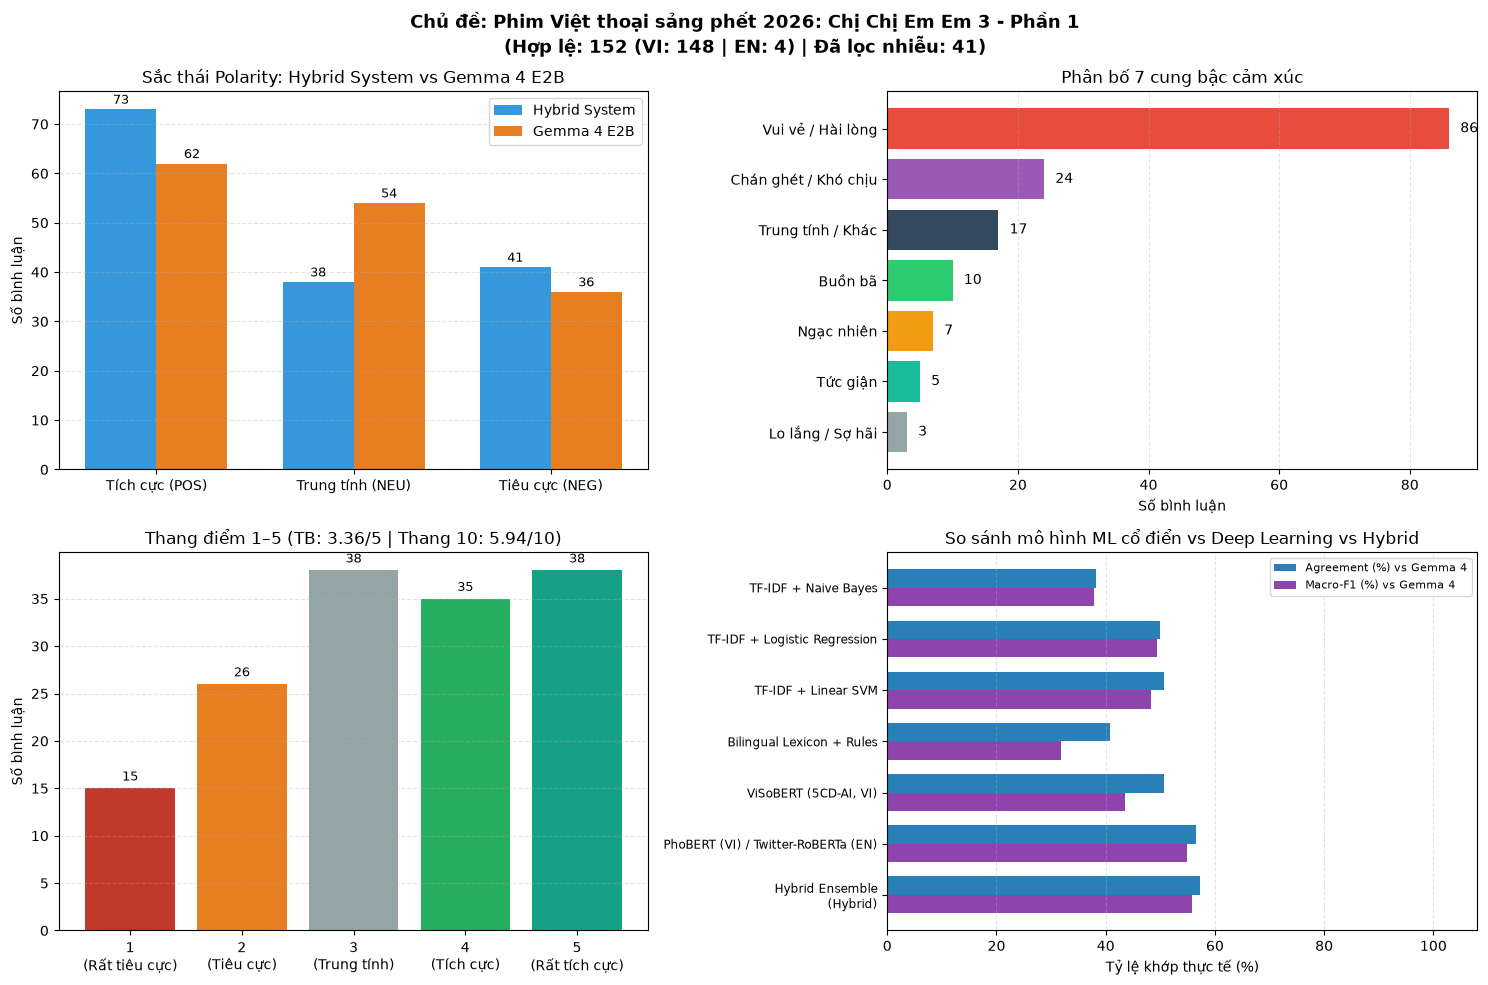

In [5]:
# === DASHBOARD TRỰC QUAN HÓA ===
exported = report.get("exported_files", {})
chart_path = exported.get("dashboard_png") or (OUTPUT_DIR / report["run_name"] / "dashboard.png")
fig = plot_sentiment_dashboard(report, save_path=chart_path)
plt.show()